# 스트리밍과 content blocks

**이 노트북에서 할 일**

1. 같은 메시지를 `invoke()`로 한 번에 받고, `stream()`으로 도착하는 대로도 받습니다.
2. 도착한 스트림 청크를 합쳐 답, 사용량, 끝난 이유를 찾고 `content_blocks`를 읽습니다.
3. 사용량 받기를 끄거나 출력 상한을 12로 줄여, 스트림 청크와 기록할 값이 어떻게 달라지는지 봅니다.

**준비물** — 프로젝트 폴더 `.env` 파일의 `OPENAI_API_KEY`가 필요합니다. 데이터 파일은 없습니다.
인터넷 서비스의 모델 `gpt-5.4-mini`에 요청을 모두 4번 보냅니다. 실행 시간은 1분 안팎입니다.
예상 비용은 0.01달러 미만입니다(06절 4절에서 2026-09-17에 확인한 공식 요금 기준).

**강의와 실습 범위** — 강의 시간에는 3~7절(invoke와 stream, 글자 없는 스트림 청크, 합치기)을 설명합니다.
8~11절(content_blocks, 값 바꿔 보기, 결과 해석)은 함께 실행하고 실습 시간에 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
함께 설치되는 openai 패키지는 3.10.0이고, python-dotenv는 1.2.3입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part2/ch06-langchain-start`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

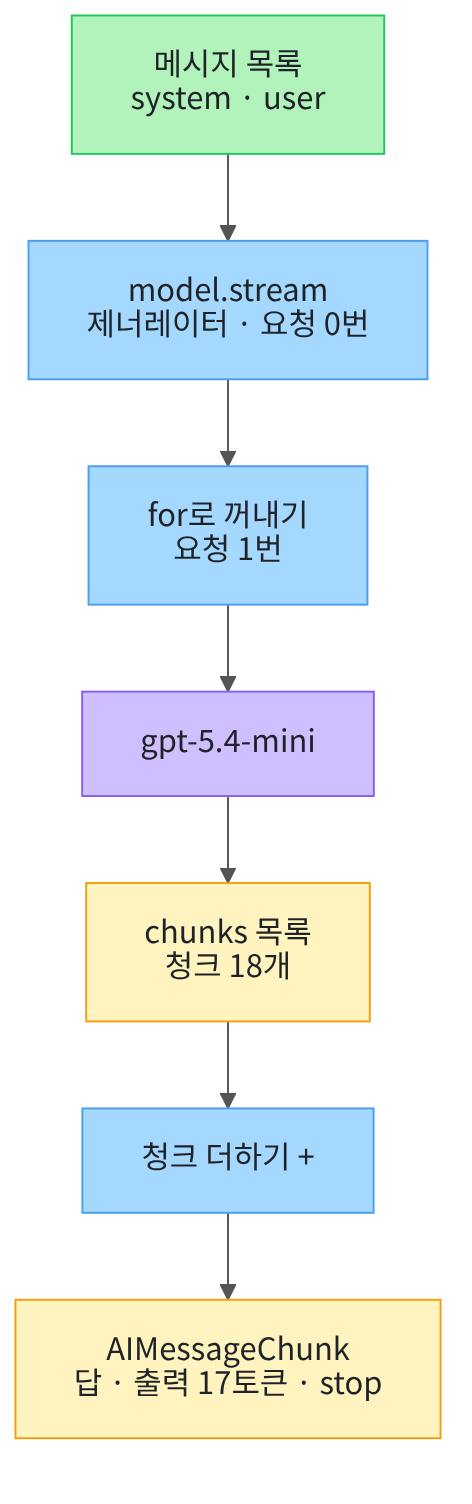

위에서 아래로 읽습니다. 초록 상자는 보낼 메시지 목록이고, 파란 상자는 우리가 적은 코드 줄입니다.
메서드 `stream()`을 부르는 줄은 요청을 보내지 않습니다. 요청은 `for`가 첫 스트림 청크를 꺼낼 때 나갑니다.

노란 상자 두 개는 출력으로 확인한 값입니다. 도착한 스트림 청크를 목록에 모은 뒤, 더해서 하나로 합칩니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
패키지 openai는 langchain-openai가 OpenAI 서버에 요청을 보낼 때 쓰는 패키지입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("openai:", version("openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.


langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
openai: 3.10.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄은 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `openai: 3.10.0` 등 다섯 줄입니다.
준비물에 적은 기준 버전과 같습니다.

01절과 같이 모델 객체를 만드는 함수를 불러옵니다.

In [2]:
# 모델 객체를 만드는 함수를 불러옵니다
from langchain.chat_models import init_chat_model

01절과 같은 셀로 API 키가 있는지 확인합니다. 키 값은 출력하지 않고, 있는지만 봅니다.
`True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
01절과 같은 설정으로 모델 객체를 만듭니다. 이 셀은 요청을 보내지 않습니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 출력 줄은 `모델 이름: gpt-5.4-mini`와 `temperature: 0.0`입니다. 이것으로 준비가 끝났습니다.
이 노트북의 출력은 2026-09-17에 이 모델로 실행한 결과입니다. 실행마다 답 문장과 스트림 청크 경계가 달라질 수 있습니다.
01절에서 본 것처럼 temperature 0은 Ch 5 06절의 뽑기를 끈 설정(`do_sample=False`)과 같은 것이 아닙니다.

## 2. 메시지 목록 만들기

이번 절의 질문은 LangChain 스트리밍을 짧게 설명해 달라는 요청입니다. system 지시는 02절의 「한 문장의 한국어로 답하세요.」를 다시 씁니다.
01절처럼 `(역할, 내용)` 튜플 목록으로 적고, 한 줄씩 출력합니다.

실행 전에 예상합니다. 역할 이름 system과 user가 한 줄씩 나올 것입니다.

In [5]:
# 한 문장으로 답하라는 공통 지시와 이번 질문을 튜플 목록에 담습니다
messages = [
    ("system", "한 문장의 한국어로 답하세요."),
    ("user", "LangChain 스트리밍을 열두 단어 이내로 설명하세요."),
]
print("메시지 목록:")
for role, content in messages:
    print(role, "|", content)

메시지 목록:
system | 한 문장의 한국어로 답하세요.
user | LangChain 스트리밍을 열두 단어 이내로 설명하세요.


**결과 읽기** — 라벨 줄 아래 첫 줄은 `system | 한 문장의 한국어로 답하세요.`입니다. 둘째 줄은 `user | LangChain 스트리밍을 열두 단어 이내로 설명하세요.`입니다.
아직 목록만 만들었고 요청은 보내지 않았습니다.

## 3. invoke()로 한 번에 받기

먼저 01절과 같은 일반 호출로 보냅니다. 메서드 `invoke()`는 답이 끝까지 만들어진 뒤에 응답 객체 하나를 반환합니다.
응답 객체의 종류, 답, 출력 토큰 수, 끝난 이유를 출력합니다. 모두 01절 노트북에서 읽은 값입니다.

실행 전에 예상합니다. 응답 객체는 AIMessage이고, 끝난 이유는 stop일 것입니다.

In [6]:
# 01절처럼 일반 호출로 보내고, 답을 다 받은 뒤 값을 읽습니다(요청 1번)
response = model.invoke(messages)
print("응답 객체 종류:", type(response).__name__)
print("답:", response.text)
print("출력 토큰 수:", response.usage_metadata["output_tokens"])
print("끝난 이유:", response.response_metadata["finish_reason"])

응답 객체 종류: AIMessage
답: LangChain 스트리밍은 생성 중 결과를 실시간 전송합니다.
출력 토큰 수: 19
끝난 이유: stop


**결과 읽기** — 출력 줄은 `응답 객체 종류: AIMessage`, 한 문장 답, `출력 토큰 수: 19`, `끝난 이유: stop`입니다.
이 셀은 답이 끝까지 만들어진 뒤에 네 줄을 출력했습니다.

답이 길면 첫 글자를 보기까지 그만큼 기다립니다. 4절부터는 같은 목록을 보내고, 답을 도착하는 대로 받습니다.

## 4. stream()을 부르는 줄

메서드 `stream()`은 `invoke()`와 같은 메시지 목록을 받습니다. 다만 완성된 답 대신, 답의 일부를 차례로 꺼낼 수 있는 객체를 반환합니다.
이렇게 도착하는 답의 일부 하나를 스트림 청크(chunk)라고 부릅니다. 실에 한 알씩 꿰는 구슬 하나와 비슷합니다.

Ch 5에서 「조각」은 토큰을 뜻했습니다. 스트림 청크는 토큰과 단위가 달라서 다른 이름으로 부릅니다.
아래 셀은 `stream()`을 부르기만 하고, 스트림 청크를 꺼내지는 않습니다. 사용량을 함께 받는 설정 `stream_usage`도 출력합니다.

실행 전에 예상합니다. 01절의 모델 객체를 만든 줄처럼, 이 줄에서는 아직 요청이 나가지 않을 것입니다.

In [7]:
# stream()을 부르기만 하고, 받은 객체의 종류와 사용량 설정을 봅니다(이 셀은 요청을 보내지 않습니다)
answer_stream = model.stream(messages)
print("stream이 준 객체 종류:", type(answer_stream).__name__)
print("stream_usage 설정:", model.stream_usage)

stream이 준 객체 종류: generator
stream_usage 설정: True


**결과 읽기** — 첫 줄은 `stream이 준 객체 종류: generator`이고, 둘째 줄은 `stream_usage 설정: True`입니다.
제너레이터(generator)는 값을 미리 만들어 두지 않고, `for`가 하나를 꺼낼 때마다 다음 값을 만드는 객체입니다.

그래서 이 줄에서는 요청이 나가지 않았습니다. 설치한 langchain-core 1.6.2 소스에서, 첫 스트림 청크를 꺼낼 때 요청을 보내는 것을 확인했습니다.
설정 `True`는 끝 쪽에 사용량을 담은 스트림 청크도 함께 받는다는 뜻입니다. 설치한 langchain-openai 1.6.0이 기본으로 켜 두는 값입니다.

## 5. 도착하는 대로 받기

4절의 객체 `answer_stream`에서 `for`로 스트림 청크를 하나씩 꺼냅니다. 첫 스트림 청크를 꺼낼 때 요청 1번이 나갑니다.
스트림 청크마다 목록 `chunks`에 담고, 스트림 청크의 글 `chunk.text` 뒤에 `|`를 붙여 글 `shown_text`에 모읍니다. 속성 `text`는 01절 응답 객체에서 읽은 그 속성입니다.

반복이 끝나면 모은 글을 한 번에 출력합니다. 기호 `|`와 `|` 사이가 스트림 청크 하나입니다.
셀 주석과 출력 라벨의 「청크」는 스트림 청크를 줄여 쓴 말입니다.

실행 전에 예상합니다. `|` 사이에 낱말이 하나씩 들어 있을 것 같지만, 실제 경계는 다를 수 있습니다.

In [8]:
# 청크를 도착하는 대로 꺼내 목록에 담고, 청크 경계에 |를 넣어 글을 모읍니다(요청 1번)
chunks = []
shown_text = ""
for chunk in answer_stream:
    chunks.append(chunk)
    shown_text = shown_text + chunk.text + "|"
print("청크 경계를 | 로 표시한 글:")
print(shown_text)
print("받은 청크 수:", len(chunks))

청크 경계를 | 로 표시한 글:
|토|큰|을| 실|시간|으로| 순|차| 전|송|하는| 기능|입니다|.||||
받은 청크 수: 18


**결과 읽기** — 라벨 줄 아래 글은 `|토|큰|을| 실|시간|으로|`로 시작하고, `기능|입니다|.||||`로 끝납니다. 마지막 줄은 `받은 청크 수: 18`입니다.
스트림 청크의 경계는 낱말과 달랐습니다. 낱말 「토큰을」이 `토`, `큰`, `을` 세 스트림 청크로 나뉘어 도착했습니다.

맨 앞의 `|`와 끝의 겹친 `|`는 글자가 없는 스트림 청크입니다. 6절에서 이 스트림 청크들을 살펴봅니다.
채팅 화면처럼 도착할 때마다 보여 주려면, 반복문 안에서 스트림 청크의 글을 바로 출력합니다. 이 노트북은 출력을 한 덩어리로 남기려고 반복이 끝난 뒤 출력했습니다.

이번에는 이미 끝까지 꺼낸 같은 객체 `answer_stream`에서 한 번 더 꺼내 봅니다. 꺼낸 스트림 청크 수를 셉니다.

실행 전에 예상합니다. 제너레이터는 끝까지 꺼냈으므로, 새 요청 없이 0개일 것입니다.

In [9]:
# 이미 끝까지 꺼낸 answer_stream에서 다시 꺼내 청크 수를 셉니다(요청 없음)
again_count = 0
for chunk in answer_stream:
    again_count = again_count + 1
print("다시 꺼낸 청크 수:", again_count)
assert again_count == 0

다시 꺼낸 청크 수: 0


**결과 읽기** — 출력 줄은 `다시 꺼낸 청크 수: 0`이고, `assert`도 통과했습니다.
한 번 끝까지 꺼낸 제너레이터는 비어 있습니다. 5절 셀을 다시 실행하려면 4절 셀부터 다시 실행합니다.

## 6. 글자가 없는 스트림 청크 살펴보기

5절 출력의 맨 앞과 끝에는 글자 없이 `|`만 찍힌 스트림 청크가 있었습니다. 이 스트림 청크들이 무엇을 담았는지 봅니다.
함수 `enumerate()`는 목록의 값을 번호와 함께 꺼냅니다(Ch 2 02절). 번호는 0부터 셉니다.

글자가 없는 스트림 청크는 번호, 끝난 이유, 사용량이 있는지를 출력합니다. 글자가 든 스트림 청크는 개수만 셉니다.
메서드 `get(키)`는 키가 없으면 `None`을 줍니다(01절). 스트림 청크마다 끝난 이유가 있는지 이것으로 봅니다.

실행 전에 예상합니다. 끝난 이유와 사용량은 답의 끝 쪽 스트림 청크에 있을 것입니다.

In [10]:
# 글자가 없는 청크의 번호·끝난 이유·사용량 여부를 보고, 글자가 든 청크 수를 셉니다(요청 없음)
text_chunk_count = 0
print("글자가 없는 청크:")
for number, chunk in enumerate(chunks):
    if chunk.text == "":
        finish_reason = chunk.response_metadata.get("finish_reason")
        has_usage = chunk.usage_metadata is not None
        print(number, "| 끝난 이유:", finish_reason, "| 사용량 있음:", has_usage)
    else:
        text_chunk_count = text_chunk_count + 1
print("글자가 든 청크 수:", text_chunk_count)

글자가 없는 청크:
0 | 끝난 이유: None | 사용량 있음: False
15 | 끝난 이유: stop | 사용량 있음: False
16 | 끝난 이유: None | 사용량 있음: True
17 | 끝난 이유: None | 사용량 있음: False
글자가 든 청크 수: 14


**결과 읽기** — 라벨 줄 아래는 네 줄이고, 번호 `0`인 첫 스트림 청크에는 끝난 이유도 사용량도 없습니다.
끝난 이유는 `15 | 끝난 이유: stop | 사용량 있음: False` 줄에 있습니다. 사용량은 그다음 `16` 줄에 있습니다.

마지막 `17`번 스트림 청크도 글자가 없습니다. 설치한 langchain-core 1.6.2 소스에서, 스트림 끝에 빈 스트림 청크 하나를 붙이는 것을 확인했습니다.
마지막 줄은 `글자가 든 청크 수: 14`입니다. 받은 스트림 청크 18개 가운데 넷은 글자가 없었습니다.

## 7. 스트림 청크 합치기

스트림 청크 하나하나는 LangChain 메시지 객체입니다. 그래서 연산자 `+`로 더할 수 있습니다.
더하면 글은 순서대로 이어지고, 사용량과 끝난 이유도 한 객체에 모입니다. 설치한 langchain-core 1.6.2 소스로 확인한 더하기 규칙입니다.

첫 스트림 청크 `chunks[0]`을 시작 값으로 두고, 나머지 `chunks[1:]`을 차례로 더합니다. 슬라이싱 `[1:]`은 Ch 2 03절에서 배웠습니다.
마지막 줄은 3절 `invoke()` 답과 글이 같은지 비교한 결과입니다. 비교 결과는 02절처럼 변수에 담아 출력합니다.

실행 전에 예상합니다. 합친 객체의 종류는 3절의 AIMessage와 다를 것입니다.

In [11]:
# 첫 청크에 나머지 청크를 차례로 더해 하나로 합칩니다(요청 없음)
combined = chunks[0]
for chunk in chunks[1:]:
    combined = combined + chunk
same_as_invoke = combined.text == response.text
print("합친 객체 종류:", type(combined).__name__)
print("합친 답:", combined.text)
print("출력 토큰 수:", combined.usage_metadata["output_tokens"])
print("끝난 이유:", combined.response_metadata["finish_reason"])
print("3절 invoke 답과 글이 같은가:", same_as_invoke)

합친 객체 종류: AIMessageChunk
합친 답: 토큰을 실시간으로 순차 전송하는 기능입니다.
출력 토큰 수: 17
끝난 이유: stop
3절 invoke 답과 글이 같은가: False


**결과 읽기** — 첫 줄은 `합친 객체 종류: AIMessageChunk`입니다. 아래로 `출력 토큰 수: 17`과 `끝난 이유: stop`이 이어집니다.
합친 객체 하나에서 3절과 같은 이름으로 사용량과 끝난 이유를 읽었습니다.

6절에서 글자가 든 스트림 청크는 14개였고, 출력 토큰은 17개로 두 수가 달랐습니다. 사용량 토큰은 제공자가 센 값이라, 스트림 청크를 세어 대신하지 않습니다.

마지막 줄은 `3절 invoke 답과 글이 같은가: False`입니다. 3절 답은 「LangChain 스트리밍은」으로 시작했고, 이번 답은 「토큰을」로 시작했습니다.
temperature 0이어도 따로 보낸 요청의 답은 같다고 보장하지 않습니다. 다시 실행하면 두 답이 같게 나와 `True`일 수도 있습니다.

스트림 청크의 글만 모아도 같은 문장이 될까요? 빈 글 `""`에서 시작해, 스트림 청크마다 `chunk.text`를 이어 붙입니다.

실행 전에 예상합니다. 문장은 합친 답과 같지만, 이어 붙인 글에는 사용량과 끝난 이유가 없을 것입니다.

In [12]:
# 청크의 글만 이어 붙인 글을 만들고, 합친 답의 글과 비교합니다(요청 없음)
joined_text = ""
for chunk in chunks:
    joined_text = joined_text + chunk.text
same_text = joined_text == combined.text
print("이어 붙인 글의 자료형:", type(joined_text).__name__)
print("두 글이 같은가:", same_text)
assert same_text

이어 붙인 글의 자료형: str
두 글이 같은가: True


**결과 읽기** — 출력 줄은 `이어 붙인 글의 자료형: str`과 `두 글이 같은가: True`입니다. `assert`도 통과했습니다.
글만 이어 붙여도 문장은 같았습니다. 하지만 자료형 str인 글에는 사용량과 끝난 이유를 담을 곳이 없습니다.

화면에 보여 줄 글만 필요하면 글을 이어 붙여도 됩니다. 사용량과 끝난 이유까지 기록하려면 스트림 청크를 `+`로 합칩니다.

## 8. content, text, content_blocks

메시지 객체에는 답의 내용을 읽는 속성이 셋 있습니다. 속성 `content`는 제공자에게서 받은 내용을 담은 값입니다.
속성 `text`는 그 내용에서 글 부분만 꺼낸 값입니다. 속성 `content_blocks`는 내용을 종류가 붙은 딕셔너리 목록으로 보여 줍니다.

이 딕셔너리 하나를 내용 블록(content block)이라고 부릅니다. 합친 답과 0번·1번 스트림 청크에서 이 값들을 출력합니다.

실행 전에 예상합니다. 글자가 없는 0번 스트림 청크의 블록 목록은 비어 있을 것입니다.

In [13]:
# 합친 답과 0번·1번 청크의 content와 content_blocks를 나란히 봅니다(요청 없음)
print("합친 답 content 자료형:", type(combined.content).__name__)
print("합친 답 content:", combined.content)
print("합친 답 content_blocks:", combined.content_blocks)
print("0번 청크 content_blocks:", chunks[0].content_blocks)
print("1번 청크 content_blocks:", chunks[1].content_blocks)

합친 답 content 자료형: str
합친 답 content: 토큰을 실시간으로 순차 전송하는 기능입니다.
합친 답 content_blocks: [{'type': 'text', 'text': '토큰을 실시간으로 순차 전송하는 기능입니다.'}]
0번 청크 content_blocks: []
1번 청크 content_blocks: [{'type': 'text', 'text': '토'}]


**결과 읽기** — 첫 줄은 `합친 답 content 자료형: str`이고, 둘째 줄은 7절의 합친 답과 같은 문장입니다.
셋째 줄은 `[{'type': 'text', 'text': '토큰을`로 시작하는, 블록 하나짜리 목록입니다.

블록에는 키 `type`에 종류, 키 `text`에 글이 들어 있습니다. 넷째 줄은 `0번 청크 content_blocks: []`로 빈 목록입니다.
다섯째 줄은 `1번 청크 content_blocks: [{'type': 'text', 'text': '토'}]`입니다. 글자가 든 스트림 청크는 글 블록 하나를 가졌습니다.

이번 답에는 종류가 text인 블록만 있었습니다. 추론, 그림, 도구 호출 같은 다른 종류의 블록은 이번에 받지 않았습니다.

## 9. 값 바꿔 보기 1 — 사용량이 든 스트림 청크 받지 않기

바꾸는 값은 `stream()`에 넘기는 인자 `stream_usage` 하나입니다. 4절에서 `True`였던 값을 `False`로 줍니다.
메시지 목록과 모델 객체는 그대로 씁니다. 이번에는 `for` 줄에서 `stream()`을 바로 부르고, 7절처럼 스트림 청크를 합칩니다.

실행 전에 예상합니다. 6절의 사용량이 든 스트림 청크 하나가 빠지고, 합친 답의 사용량은 `None`일 것입니다.

In [14]:
# 인자 stream_usage=False로 같은 질문을 스트리밍하고 청크를 합칩니다(요청 1번)
no_usage_chunks = []
for chunk in model.stream(messages, stream_usage=False):
    no_usage_chunks.append(chunk)
no_usage_combined = no_usage_chunks[0]
for chunk in no_usage_chunks[1:]:
    no_usage_combined = no_usage_combined + chunk
print("받은 청크 수:", len(no_usage_chunks))
print("합친 답:", no_usage_combined.text)
print("사용량:", no_usage_combined.usage_metadata)
print("끝난 이유:", no_usage_combined.response_metadata["finish_reason"])

받은 청크 수: 17
합친 답: 토큰을 실시간으로 순차 전송하는 기능입니다.
사용량: None
끝난 이유: stop


**결과 읽기** — 출력 줄은 `받은 청크 수: 17`, 한 문장 답, `사용량: None`, `끝난 이유: stop`입니다.
5절보다 스트림 청크가 하나 적습니다. 답과 끝난 이유는 받았지만 사용량은 없습니다.

사용량이 없다고 토큰을 쓰지 않은 것은 아닙니다. 요청 1번을 보내 답을 받았으므로 토큰은 쓰였습니다.

그러면 기록표에는 출력 토큰 수를 무엇으로 적어야 할까요? 02절 기록표는 출력 토큰 수를 모르는 줄에 0이 아니라 `None`을 적었습니다.
여기서도 사용량이 있을 때만 출력 토큰 수를 꺼내고, 없으면 `None`으로 둡니다.

실행 전에 예상합니다. 기록할 값은 0이 아니라 `None`일 것입니다.

In [15]:
# 사용량이 있을 때만 출력 토큰 수를 꺼내고, 없으면 None으로 둡니다(요청 없음)
no_usage_metadata = no_usage_combined.usage_metadata
if no_usage_metadata is None:
    no_usage_tokens = None
else:
    no_usage_tokens = no_usage_metadata["output_tokens"]
print("기록할 출력 토큰 수:", no_usage_tokens)
assert no_usage_tokens is None

기록할 출력 토큰 수: None


**결과 읽기** — 출력 줄은 `기록할 출력 토큰 수: None`이고, `assert`도 통과했습니다.
0으로 적으면 토큰을 하나도 쓰지 않은 호출처럼 보입니다. 모르는 값은 `None`으로 남깁니다.

## 10. 값 바꿔 보기 2 — 출력 상한 12로 줄이기

이번에 바꾸는 값은 출력 상한 하나입니다. 01절 노트북 7절처럼 인자 `max_tokens=12`를 준 새 모델 객체를 만듭니다.
사용량 설정은 4절과 같은 기본값이고, 메시지 목록도 그대로입니다. 이 셀은 요청을 보내지 않습니다.

실행 전에 예상합니다. 출력 상한은 01절 노트북 7절과 같은 12로 보일 것입니다.

In [16]:
# 01절처럼 출력 상한 12인 모델 객체를 만듭니다(이 셀은 요청을 보내지 않습니다)
short_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    max_tokens=12,
)
print("출력 상한(max_tokens):", short_model.max_tokens)

출력 상한(max_tokens): 12


**결과 읽기** — 출력 줄은 `출력 상한(max_tokens): 12`입니다. 01절 노트북 7절과 같은 값입니다.

이 모델 객체로 같은 질문을 스트리밍합니다. 5절처럼 스트림 청크 경계에 `|`를 넣어 글을 모은 뒤 출력합니다.

실행 전에 예상합니다. 답이 중간에 끊겨도 스트림 청크는 오류 없이 도착할 것입니다.

In [17]:
# 출력 상한 12인 모델 객체로 같은 질문을 스트리밍하고, 청크 경계에 |를 넣어 글을 모읍니다(요청 1번)
short_chunks = []
short_shown_text = ""
for chunk in short_model.stream(messages):
    short_chunks.append(chunk)
    short_shown_text = short_shown_text + chunk.text + "|"
print("청크 경계를 | 로 표시한 글:")
print(short_shown_text)

청크 경계를 | 로 표시한 글:
|토|큰|을| 실|시간|으로| 순|차| 전||||


**결과 읽기** — 라벨 줄 아래 글은 `|토|큰|을| 실|시간|으로| 순|차| 전||||`입니다. 글이 「순차 전」에서 멈췄습니다.
오류 없이 셀이 끝났습니다. 화면에 글이 찍혔다고 해서, 답이 끝까지 온 것은 아닙니다.

끊겼는지는 스트림 청크를 합쳐 끝난 이유로 확인합니다. 7절과 같은 방법으로 합치고, 스트림 청크 수와 출력 토큰 수도 출력합니다.

실행 전에 예상합니다. 출력 토큰 수는 상한과 같고, 끝난 이유는 01절에서 본 length일 것입니다.

In [18]:
# 출력 상한 12로 받은 청크를 합쳐 출력 토큰 수와 끝난 이유를 봅니다(요청 없음)
short_combined = short_chunks[0]
for chunk in short_chunks[1:]:
    short_combined = short_combined + chunk
print("받은 청크 수:", len(short_chunks))
print("합친 답:", short_combined.text)
print("출력 토큰 수:", short_combined.usage_metadata["output_tokens"])
print("끝난 이유:", short_combined.response_metadata["finish_reason"])

받은 청크 수: 13
합친 답: 토큰을 실시간으로 순차 전
출력 토큰 수: 12
끝난 이유: length


**결과 읽기** — 출력 줄은 `받은 청크 수: 13`, `합친 답: 토큰을 실시간으로 순차 전`, `출력 토큰 수: 12`, `끝난 이유: length`입니다.
01절에서 본 것처럼 끝난 이유 `length`는 출력 상한에 닿아 멈췄다는 뜻입니다.

6절에서 본 대로, 기본 스트리밍의 끝난 이유는 글자가 없는 15번 스트림 청크에 있었습니다. 글만 이어 붙여 저장하면 끊긴 답인지 알 수 없습니다.

## 11. 실험 결과 해석 — 세 번의 스트리밍 비교

5절 기본, 9절 사용량 끔, 10절 출력 상한 12의 결과를 한 줄씩 나란히 출력합니다.
사용량을 끈 줄의 출력 토큰 수는 9절에서 기록한 값 `no_usage_tokens`를 씁니다. 표 모양은 라벨 줄을 따로 출력합니다.

실행 전에 예상합니다. 사용량을 끈 줄만 출력 토큰 수가 `None`일 것입니다.

In [19]:
# 세 번의 스트리밍 결과를 한 줄씩 나란히 출력합니다(요청 없음)
base_tokens = combined.usage_metadata["output_tokens"]
short_tokens = short_combined.usage_metadata["output_tokens"]
base_finish = combined.response_metadata["finish_reason"]
no_usage_finish = no_usage_combined.response_metadata["finish_reason"]
short_finish = short_combined.response_metadata["finish_reason"]
print("실행 | 청크 수 | 출력 토큰 수 | 끝난 이유")
print("기본 |", len(chunks), "|", base_tokens, "|", base_finish)
print("사용량 끔 |", len(no_usage_chunks), "|", no_usage_tokens, "|", no_usage_finish)
print("출력 상한 12 |", len(short_chunks), "|", short_tokens, "|", short_finish)

실행 | 청크 수 | 출력 토큰 수 | 끝난 이유
기본 | 18 | 17 | stop
사용량 끔 | 17 | None | stop
출력 상한 12 | 13 | 12 | length


**결과 읽기** — 라벨 줄 아래 세 줄은 `기본 | 18 | 17 | stop`, `사용량 끔 | 17 | None | stop`, `출력 상한 12 | 13 | 12 | length`입니다.
스트림 청크 수는 세 번 모두 달랐습니다.

사용량을 끈 줄은 답을 받았는데도 출력 토큰 수가 `None`입니다. 모르는 값을 0으로 채우지 않았습니다.
출력 상한 12인 줄만 끝난 이유가 `length`입니다. 셋 다 오류 없이 끝났으므로, 끝났는지는 이 값으로 구분합니다.

이 표는 설정마다 한 번씩 실행한 결과입니다. 스트림 청크 수로 모델의 속도나 답의 품질을 비교하지 않습니다.

## 정리

- 메서드 `invoke()`는 답을 다 받은 뒤 `AIMessage` 하나를 반환했습니다. 메서드 `stream()`은 제너레이터를 반환했고, `for`로 꺼낼 때 요청이 나갔습니다.
- 스트림 청크 18개를 `+`로 합치자 글, 사용량, 끝난 이유가 `AIMessageChunk` 하나에 모였습니다. 끝난 이유와 사용량은 글자가 없는 끝 쪽 스트림 청크에 있었습니다.
- 사용량 받기를 끄면 출력 토큰 수를 `None`으로 적었고, 출력 상한 12에서는 오류 없이 끊겨 끝난 이유가 `length`였습니다.

다음 05절에서는 요청이 늦거나 오류가 날 때를 다룹니다. 기다리는 시간과 다시 시도하는 횟수를 정하고, 실패하면 쓸 다른 경로를 준비합니다.